## Test training


In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.sampler
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer
%aimport quantdata.dysanos.simple.aec

from quantdata.dysanos.simple.aec import load_data
sampler = load_data(["SPX"])
print("/done")



00: Importing torch...done; this took 0.00691ms.
00: Generating samples for 1 tickers SPX with from 2015-01-01 to 2025-07-01... done; this took 0.27s.
00: Found the following number of samples per ticker: SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 0.31s.
/done


## AEC

Cleaning up memory... done.
Model AEC train_sqrtVar_vol_attn 1.1 [c5d14e38|acaee5f1ce9f88de] created.
00: Trainer for 'AEC train_sqrtVar_vol_attn 1.1 [c5d14e38|acaee5f1ce9f88de]' on data acaee5f1ce9f88de
00: =================================================================================================
01:   Model is ready. Current epoch to train is 0.
01:   Experiment path is /media/storage/quantdata/experiments/dysanos/simple/acaee5f1ce9f88de/v1/train_sqrtVar_vol_attn 705da9d8/.
00: Launching 'AEC train_sqrtVar_vol_attn 1.1 [c5d14e38|acaee5f1ce9f88de]' training for 1000 epochs over 411 training and 103 validation samples, using a mini bastch size of 128 for 10 batches per epoch, and a batch size of 256 for valuation. The model has 47849 parameters.
00: Training 'train_sqrtVar_vol_attn' epoch 1/1000 error avg trn 1605; val 751.9/1508 [12s 1.5s 0.36s]. LR: 1.00e-03, GN 395.2, excess_weighted: 1.938e-12/2.898e-12, excess_weighted_avg: 0.07086/0.07662, excess_spread: 577.2/807.1, exces

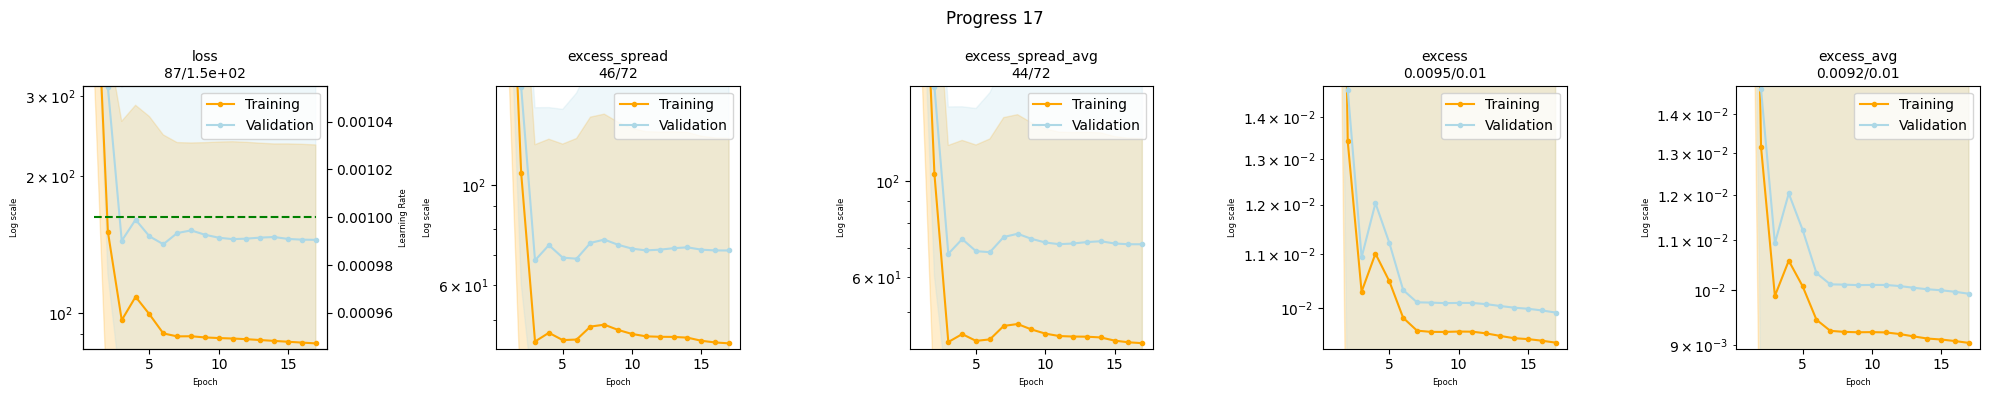

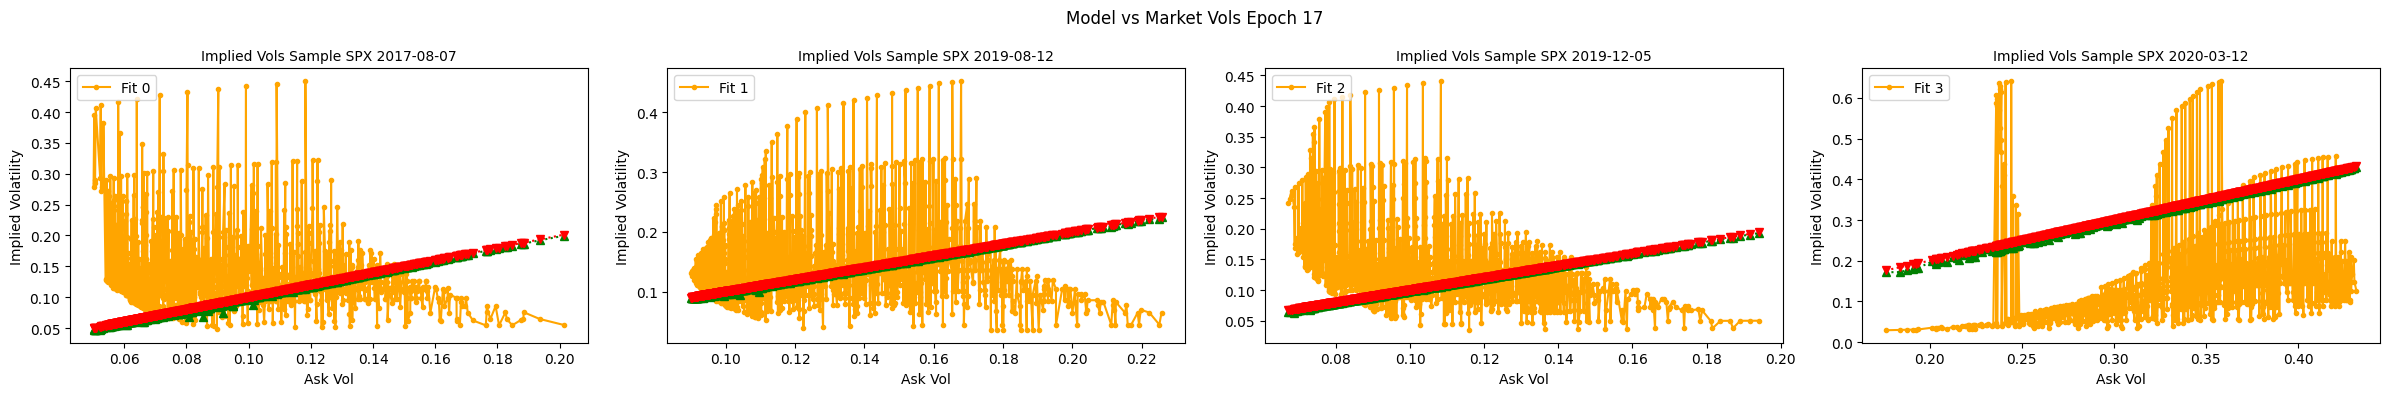

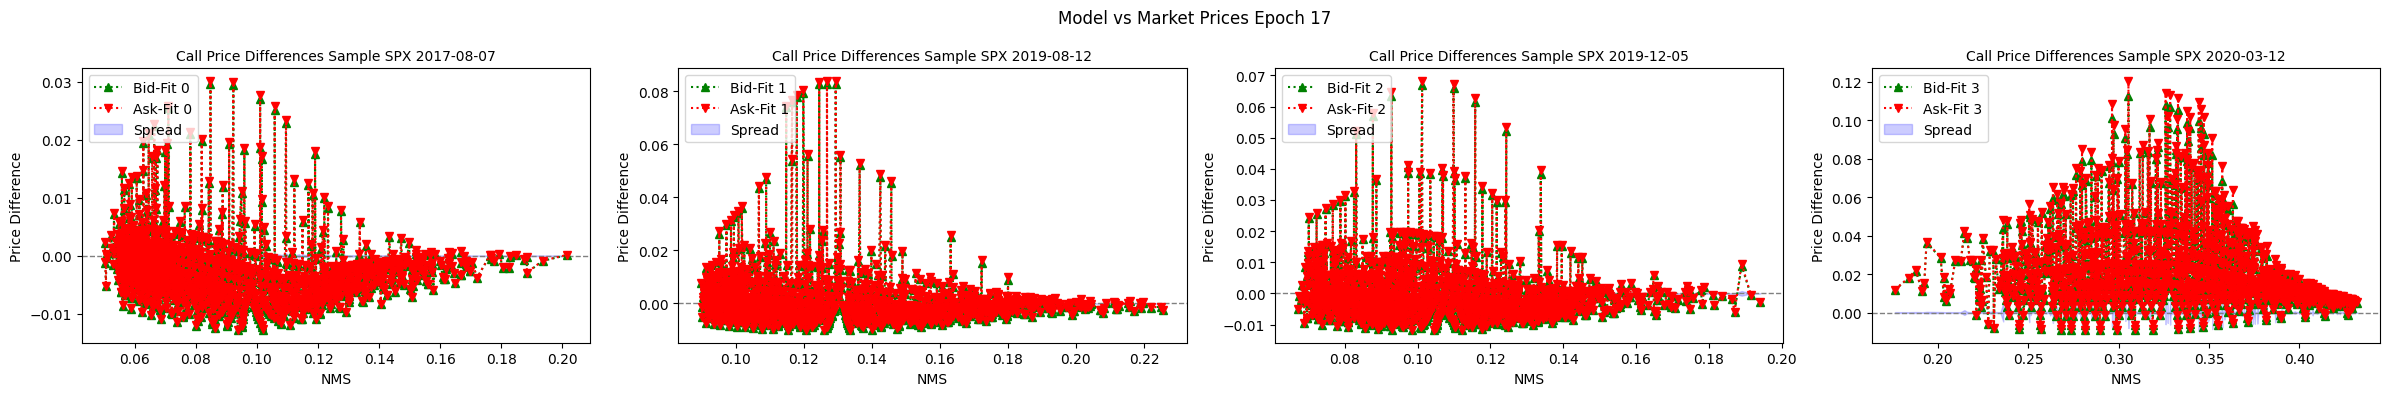

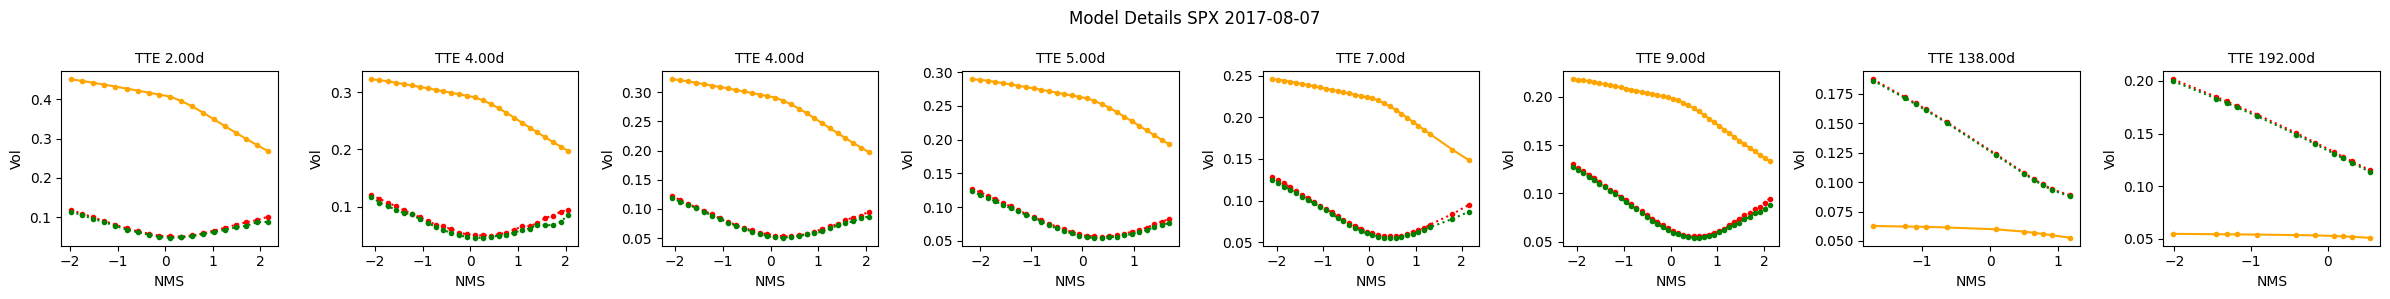

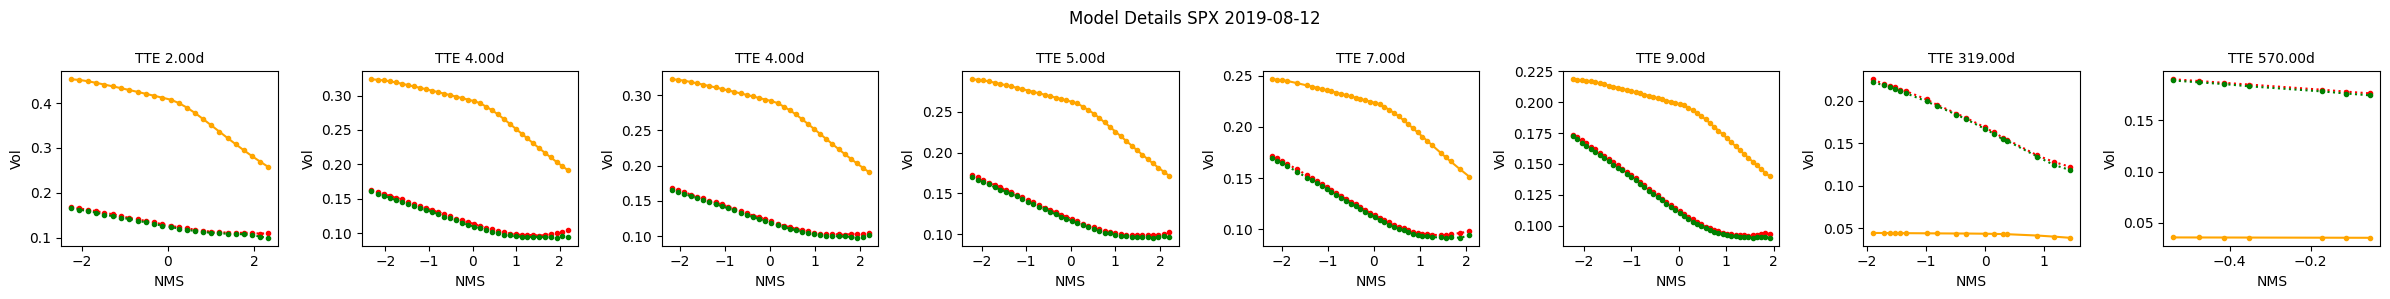

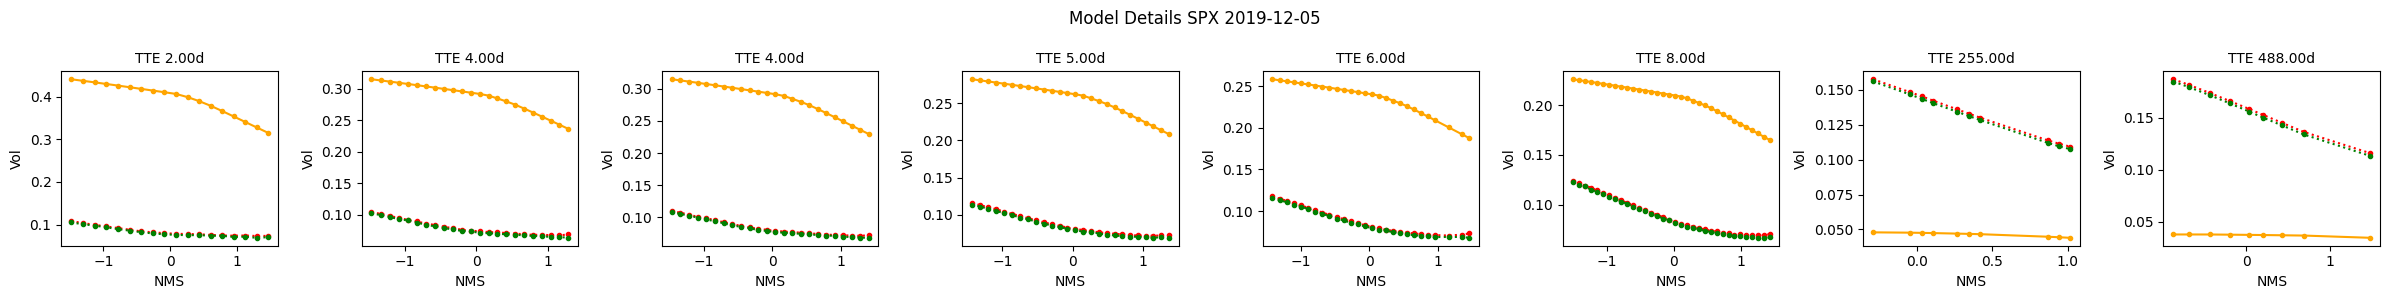

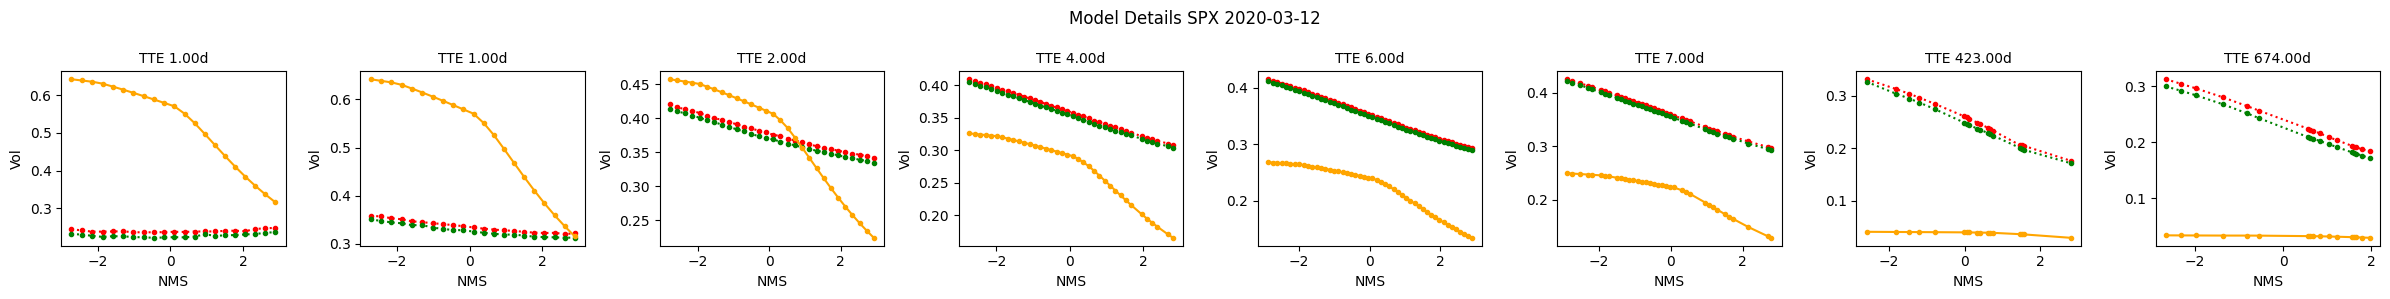

00: Training 'train_sqrtVar_vol_attn' epoch 2/1000 error avg trn 423.2; val 151/314.1 [11s 1.5s 0.36s]. LR: 1.00e-03, GN 124.5, excess_weighted: 3.571e-13/5.93e-13, excess_weighted_avg: 0.01291/0.0155, excess_spread: 106.5/165.2, excess_spread_avg: 103.9/165.2, excess: 0.01341/0.01469, excess_avg: 0.01315/0.01469. ETA: 8:22:51.
00: Training 'train_sqrtVar_vol_attn' epoch 3/1000 error avg trn 104.1; val 96.49/144.2 [11s 1.5s 0.36s]. LR: 1.00e-03, GN 19.75, excess_weighted: 1.492e-13/2.442e-13, excess_weighted_avg: 0.006592/0.007233, excess_spread: 44.89/68.01, excess_spread_avg: 42.52/68.01, excess: 0.01029/0.01094, excess_avg: 0.009884/0.01094. ETA: 12:43:57.
00: Training 'train_sqrtVar_vol_attn' epoch 4/1000 error avg trn 102.6; val 108.6/160.5 [11s 1.5s 0.36s]. LR: 1.00e-03, GN 30.09, excess_weighted: 1.559e-13/2.64e-13, excess_weighted_avg: 0.006972/0.00791, excess_spread: 46.94/73.54, excess_spread_avg: 44.36/73.54, excess: 0.01101/0.01203, excess_avg: 0.01057/0.01203. ETA: 16:59:3

In [ ]:
from quantdata.dysanos.simple.model import *
from quantdata.dysanos.simple.aec import *

aec_config = AEC.Config(
    # core pararmeters
    encode_what = "sqrtVar",
    fit_what    = "vol",
    num_state   = 64,
    fit_average = True,

    # rarely touch these
    weight_by_spread = True,

    encoder = AttentionEncoderFactory(
        num_head = 64,
        num_QK = 8,
        V_config = FeedForward.Config(
            num_depth = 1,
            num_width = 64, # head
            activation = 'Softplus',
        ),
        QK_config = FeedForward.Config(
            num_depth = 1,
            num_width = 16, # twice num_QK
            activation = 'ReLU', # idea is to be sparse...?
        ),
        head_config = FeedForward.Config(
            num_depth = 2,
            num_width = 64, # head
            activation = 'ReLU', # idea is to be sparse...?
        )
    ),
    decoder = GatingDecoderFactory(
        num_head = 16,
        num_QK = 4,        
        V_config = FeedForward.Config(
            num_depth = 2,
            num_width = 32, # twice head
            activation = 'Softplus',    
        ),
        QK_config = FeedForward.Config(
            num_depth = 1,
            num_width = 4, # equal QK
            activation = 'ReLU', # idea is to be sparse...?
        ),
        head_config = FeedForward.Config(
            num_depth = 2,
            num_width = 32, # twice head
            activation = 'Softplus',
        )
    ),
)

run( ipynbname.name(), version="1.1", aec_config=aec_config, sampler=sampler, epochs = 1000, batch_per_epoch = 10, debug=False, val_batch_size=256 )
